# Capstone: Mini AI Cybersecurity Assistant
**Course:** ENSP355 – AI in Cyber Security | **Platform:** Jupyter Notebook / Google Colab

This guided notebook integrates a keyword/rule detector, a Decision Tree, a small neural network, explanations, privacy masking, risk scoring and human review.

**Safety:** Uses only the synthetic/sanitized CSV files supplied in this project. Do not test live accounts, open suspicious links, execute malware, scan networks, or upload confidential institutional data.

**Data note:** The capstone brief refers to supplied synthetic/sanitized data, but no separate source CSVs were attached with the assignment PDF. The two included CSVs are newly created synthetic teaching examples and are clearly labelled as such.

## 1. Architecture and workflow
1. Load message and login CSV files; validate and clean required fields.
2. Mask email, IP address and account ID before displaying results.
3. Detect phishing, malware and ransomware indicators with transparent keyword rules.
4. Train/evaluate a Decision Tree on numeric login features.
5. Scale numeric inputs and train a small neural network (MLP).
6. Compare rule, tree and neural results.
7. Explain matched keywords, feature importance and numeric warning thresholds.
8. Assign Low/Medium/High risk and safe action; request human review for High risk, disagreement or low confidence.

In [1]:
import re, warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay

RANDOM_STATE = 42
FEATURES = ["failed_logins", "login_hour", "new_device", "download_mb"]
pd.set_option("display.max_colwidth", 100)

## 2. Load, inspect and clean the two supplied CSV files

In [2]:
messages = pd.read_csv("messages.csv")
logins = pd.read_csv("login_activity.csv")

print("Message dataset shape:", messages.shape)
display(messages.head())
print("Login dataset shape:", logins.shape)
display(logins.head())

# Basic validation and cleaning
messages["message"] = messages["message"].fillna("").astype(str).str.strip()
logins[FEATURES] = logins[FEATURES].apply(pd.to_numeric, errors="coerce")
for col in FEATURES:
    logins[col] = logins[col].fillna(logins[col].median())
logins["new_device"] = logins["new_device"].clip(0, 1).astype(int)
logins["login_hour"] = logins["login_hour"].clip(0, 23)
logins["failed_logins"] = logins["failed_logins"].clip(lower=0)
logins["download_mb"] = logins["download_mb"].clip(lower=0)

print("Missing values after cleaning:")
display(pd.DataFrame({"messages_missing": messages.isna().sum(),
                      "login_missing": logins.isna().sum().reindex(messages.columns, fill_value=0)}))

Message dataset shape: (12, 3)


,scenario_id,message,category
0,S1,"Hi team, the meeting is scheduled for 10 AM. Please review the shared agenda.",Safe
1,S2,URGENT: verify your account immediately and click the link to avoid suspension.,Phishing
2,S3,Your account has repeated failed sign-in attempts from an unknown device.,Safe
3,S4,The scheduled backup completed and the report is available in the internal portal.,Safe
4,S5,Your files are encrypted. Pay the ransom to restore access.,Ransomware


Login dataset shape: (12, 9)


,scenario_id,account_id,ip_address,email,failed_logins,login_hour,new_device,download_mb,label
0,S1,ACC-2001,192.168.1.10,user1@example.test,0,10,0,35,Normal
1,S2,ACC-2002,10.1.2.30,user2@example.test,1,11,0,50,Normal
2,S3,ACC-2003,172.16.0.18,user3@example.test,8,2,1,120,Suspicious
3,S4,ACC-2004,192.168.1.44,user4@example.test,0,14,0,620,Suspicious
4,S5,ACC-2005,10.2.3.40,user5@example.test,2,9,0,80,Normal


Missing values after cleaning:


,messages_missing,login_missing
scenario_id,0,0
message,0,0
category,0,0


## 3. Privacy functions: mask email, IP and account ID

In [3]:
def mask_email(value):
    value = str(value)
    if "@" not in value:
        return "<MASKED_EMAIL>"
    local, domain = value.split("@", 1)
    visible = local[:1] if local else ""
    return f"{visible}***@{domain}"

def mask_ip(value):
    parts = str(value).split(".")
    return f"{parts[0]}.{parts[1]}.xxx.xxx" if len(parts) == 4 else "<MASKED_IP>"

def mask_account(value):
    value = str(value)
    return value[:4] + "***" + value[-2:] if len(value) > 6 else "*" * len(value)

logins["masked_account"] = logins["account_id"].apply(mask_account)
logins["masked_ip"] = logins["ip_address"].apply(mask_ip)
logins["masked_email"] = logins["email"].apply(mask_email)

display(logins[["scenario_id","masked_account","masked_ip","masked_email"]].head())

,scenario_id,masked_account,masked_ip,masked_email
0,S1,ACC-***01,192.168.xxx.xxx,u***@example.test
1,S2,ACC-***02,10.1.xxx.xxx,u***@example.test
2,S3,ACC-***03,172.16.xxx.xxx,u***@example.test
3,S4,ACC-***04,192.168.xxx.xxx,u***@example.test
4,S5,ACC-***05,10.2.xxx.xxx,u***@example.test


## 4. Rule-based threat detector

The rule module looks for indicative terms in three categories. It is intentionally transparent and simple. Keyword matches are indicators for review, not proof that a message is malicious.

In [4]:
THREAT_KEYWORDS = {
    "Phishing": ["urgent", "verify your account", "click the link", "suspension",
                 "claim your prize", "provide your password", "password now"],
    "Malware": ["malicious payload", "enable macros", "infected", "trojan",
                "malware", "suspicious attachment"],
    "Ransomware": ["ransom", "encrypted", "payment is demanded", "restore access"]
}

def rule_detector(message):
    text = str(message).lower()
    matches = {}
    for category, keywords in THREAT_KEYWORDS.items():
        found = [word for word in keywords if word in text]
        if found:
            matches[category] = found
    if not matches:
        return "Safe", [], 0
    # Return all matches but choose category with most matched indicators
    category = max(matches, key=lambda key: len(matches[key]))
    all_words = [word for words in matches.values() for word in words]
    return category, all_words, len(all_words)

messages[["rule_category","matched_keywords","keyword_score"]] = messages["message"].apply(
    lambda value: pd.Series(rule_detector(value))
)
display(messages[["scenario_id","rule_category","matched_keywords","keyword_score"]])

,scenario_id,rule_category,matched_keywords,keyword_score
0,S1,Safe,[],0
1,S2,Phishing,"[urgent, verify your account, click the link, suspension]",4
2,S3,Safe,[],0
3,S4,Safe,[],0
4,S5,Ransomware,"[ransom, encrypted, restore access]",3
5,S6,Malware,[enable macros],1
6,S7,Safe,[],0
7,S8,Safe,[],0
8,S9,Phishing,"[claim your prize, provide your password, password now]",3
9,S10,Malware,[malicious payload],1


## 5. Decision Tree: supervised login classification

Decision Tree test accuracy: 1.0
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00         2
  Suspicious       1.00      1.00      1.00         1

    accuracy                           1.00         3
   macro avg       1.00      1.00      1.00         3
weighted avg       1.00      1.00      1.00         3



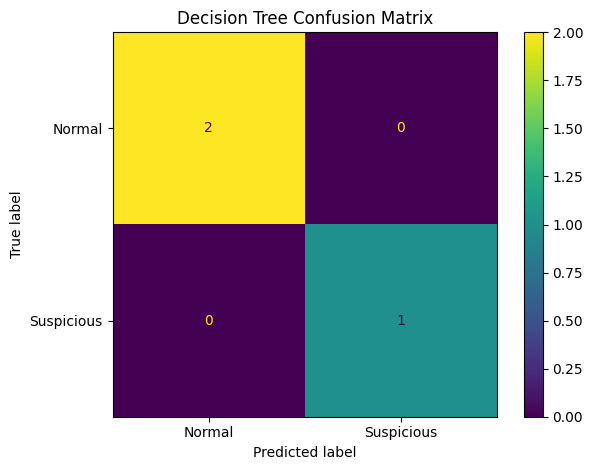

,feature,importance
3,download_mb,1.0
0,failed_logins,0.0
1,login_hour,0.0
2,new_device,0.0


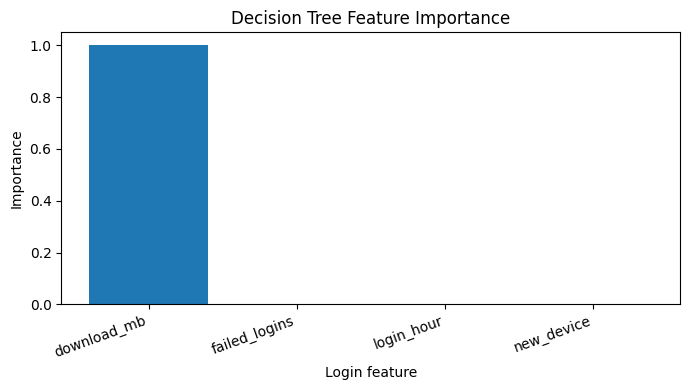

In [5]:
X = logins[FEATURES].copy()
y = logins["label"].astype(str)

# Stratify when possible; fixed random state makes the demonstration reproducible.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y
)
tree = DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE)
tree.fit(X_train, y_train)
tree_pred = tree.predict(X_test)
print("Decision Tree test accuracy:", round(accuracy_score(y_test, tree_pred), 3))
print(classification_report(y_test, tree_pred, zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test, tree_pred, labels=["Normal","Suspicious"])
plt.title("Decision Tree Confusion Matrix")
plt.tight_layout()
plt.show()

tree_importance = pd.DataFrame({
    "feature": FEATURES, "importance": tree.feature_importances_
}).sort_values("importance", ascending=False)
display(tree_importance)
plt.figure(figsize=(7,4))
plt.bar(tree_importance["feature"], tree_importance["importance"])
plt.title("Decision Tree Feature Importance")
plt.ylabel("Importance")
plt.xlabel("Login feature")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

**Feature explanation:** The feature-importance chart ranks which numeric inputs the fitted tree used most for its splits. This is a model-level description, not proof of causation. Numeric warning thresholds used later are explicit rules: at least five failed logins, a new device, login before 06:00 or after 22:00, or a download of at least 500 MB.

## 6. Small neural network: scale features and compare

In [6]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Small feed-forward neural network. Its probability output estimates the Suspicious class.
nn = MLPClassifier(hidden_layer_sizes=(8, 4), activation="relu",
                   solver="lbfgs", alpha=0.01, max_iter=1500,
                   random_state=RANDOM_STATE)
nn.fit(X_train_scaled, y_train)
nn_pred = nn.predict(X_test_scaled)
print("Neural Network test accuracy:", round(accuracy_score(y_test, nn_pred), 3))
print(classification_report(y_test, nn_pred, zero_division=0))

# Loss curve is not available for lbfgs; use a compact evaluation comparison.
model_comparison = pd.DataFrame([
    {"model":"Decision Tree","test_accuracy":accuracy_score(y_test, tree_pred)},
    {"model":"Neural Network (MLP)","test_accuracy":accuracy_score(y_test, nn_pred)}
])
display(model_comparison)

Neural Network test accuracy: 0.667
              precision    recall  f1-score   support

      Normal       1.00      0.50      0.67         2
  Suspicious       0.50      1.00      0.67         1

    accuracy                           0.67         3
   macro avg       0.75      0.75      0.67         3
weighted avg       0.83      0.67      0.67         3



,model,test_accuracy
0,Decision Tree,1.000000
1,Neural Network (MLP),0.666667


## 7. Integrated assistant: explanation, comparison, risk and response

In [7]:
def numeric_reasons(row):
    reasons = []
    if row["failed_logins"] >= 5:
        reasons.append("many failed logins (>=5)")
    if row["new_device"] == 1:
        reasons.append("new device")
    if row["login_hour"] < 6 or row["login_hour"] > 22:
        reasons.append("unusual login time (<06:00 or >22:00)")
    if row["download_mb"] >= 500:
        reasons.append("large download (>=500 MB)")
    return reasons or ["no numeric warning threshold triggered"]

def cybersecurity_assistant(message, failed_logins, login_hour, new_device,
                            download_mb, ip_address, account_id, email="unknown@example.test"):
    clean_message = re.sub(r"\s+", " ", str(message)).strip()
    rule_category, matched, keyword_score = rule_detector(clean_message)

    numeric = pd.DataFrame([{
        "failed_logins": failed_logins, "login_hour": login_hour,
        "new_device": new_device, "download_mb": download_mb
    }], columns=FEATURES)
    numeric["failed_logins"] = pd.to_numeric(numeric["failed_logins"]).clip(lower=0)
    numeric["login_hour"] = pd.to_numeric(numeric["login_hour"]).clip(0, 23)
    numeric["new_device"] = pd.to_numeric(numeric["new_device"]).clip(0, 1)
    numeric["download_mb"] = pd.to_numeric(numeric["download_mb"]).clip(lower=0)
    numeric["new_device"] = numeric["new_device"].astype(int)

    tree_prediction = tree.predict(numeric)[0]
    tree_confidence = float(tree.predict_proba(numeric).max())
    nn_prob = nn.predict_proba(scaler.transform(numeric))[0]
    nn_classes = list(nn.classes_)
    suspicious_idx = nn_classes.index("Suspicious")
    nn_suspicious_probability = float(nn_prob[suspicious_idx])
    nn_prediction = "Suspicious" if nn_suspicious_probability >= 0.5 else "Normal"
    nn_confidence = float(max(nn_prob))

    reasons = numeric_reasons(numeric.iloc[0])
    warning_votes = int(rule_category != "Safe") + int(tree_prediction == "Suspicious") + int(nn_prediction == "Suspicious")
    conflict = len({tree_prediction, nn_prediction}) > 1
    low_confidence = min(tree_confidence, nn_confidence) < 0.70

    # Message category and numeric classifiers contribute to a cautious integrated risk.
    if warning_votes >= 2 or rule_category in ["Ransomware", "Malware"] and warning_votes >= 1:
        risk = "High"
    elif warning_votes == 1 or rule_category != "Safe":
        risk = "Medium"
    else:
        risk = "Low"

    human_review = "Yes" if risk == "High" or conflict or low_confidence else "No"
    if risk == "High":
        action = "Do not interact with the message; preserve evidence and escalate to an authorized security analyst. Verify the login through an approved channel."
    elif risk == "Medium" or human_review == "Yes":
        action = "Treat cautiously; verify through an independently known official channel and request analyst review before taking action."
    else:
        action = "No immediate warning detected; continue normal monitoring and remain alert."

    return {
        "rule_category": rule_category,
        "matched_keywords": ", ".join(matched) if matched else "None",
        "keyword_score": keyword_score,
        "tree_prediction": tree_prediction,
        "tree_confidence": round(tree_confidence, 3),
        "nn_prediction": nn_prediction,
        "nn_confidence": round(nn_confidence, 3),
        "nn_suspicious_probability": round(nn_suspicious_probability, 3),
        "warning_votes": warning_votes,
        "numeric_reasons": "; ".join(reasons),
        "risk": risk,
        "recommended_action": action,
        "human_review": human_review,
        "model_conflict": conflict,
        "masked_account": mask_account(account_id),
        "masked_ip": mask_ip(ip_address),
        "masked_email": mask_email(email)
    }

## 8. Run the five required demonstration scenarios

In [8]:
scenario_messages = messages.set_index("scenario_id")["message"].to_dict()
scenario_map = {
    "S1": "Scenario 1 – Normal message + normal login",
    "S2": "Scenario 2 – Urgent account-verification message",
    "S3": "Scenario 3 – Repeated failed logins on a new device",
    "S4": "Scenario 4 – Large download at an unusual time",
    "S5": "Scenario 5 – Conflicting/low-confidence review case"
}

# Scenario 5 is deliberately chosen as a borderline/conflict review test case.
scenario_inputs = [
    ("S1", 0, 10, 0, 35),
    ("S2", 1, 11, 0, 50),
    ("S3", 8, 2, 1, 120),
    ("S4", 0, 3, 0, 620),
    ("S5", 2, 9, 0, 80),
]
rows = []
for sid, failed, hour, device, download in scenario_inputs:
    login = logins.loc[logins["scenario_id"] == sid].iloc[0]
    result = cybersecurity_assistant(
        scenario_messages[sid], failed, hour, device, download,
        login["ip_address"], login["account_id"], login["email"]
    )
    result["scenario_id"] = sid
    result["scenario"] = scenario_map[sid]
    rows.append(result)

results = pd.DataFrame(rows)
display(results[[
    "scenario_id","scenario","rule_category","matched_keywords",
    "tree_prediction","tree_confidence","nn_prediction","nn_confidence",
    "numeric_reasons","risk","human_review"
]])

,scenario_id,scenario,rule_category,matched_keywords,tree_prediction,tree_confidence,nn_prediction,nn_confidence,numeric_reasons,risk,human_review
0,S1,Scenario 1 – Normal message + normal login,Safe,None,Normal,1.0,Normal,1.000,no numeric warning threshold triggered,Low,No
1,S2,Scenario 2 – Urgent account-verification message,Phishing,"urgent, verify your account, click the link, suspension",Normal,1.0,Normal,1.000,no numeric warning threshold triggered,Medium,No
2,S3,Scenario 3 – Repeated failed logins on a new device,Safe,None,Suspicious,1.0,Suspicious,0.999,many failed logins (>=5); new device; unusual login time (<06:00 or >22:00),High,Yes
3,S4,Scenario 4 – Large download at an unusual time,Safe,None,Suspicious,1.0,Suspicious,0.999,unusual login time (<06:00 or >22:00); large download (>=500 MB),High,Yes
4,S5,Scenario 5 – Conflicting/low-confidence review case,Ransomware,"ransom, encrypted, restore access",Normal,1.0,Normal,0.998,no numeric warning threshold triggered,High,Yes


## 9. Risk/category chart and final combined result table

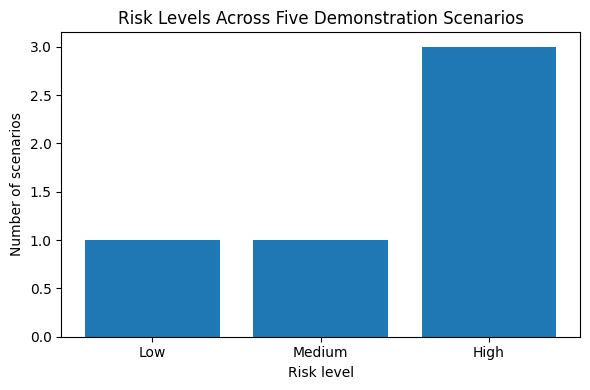

,scenario_id,scenario,masked_account_login,masked_ip_login,masked_email_login,rule_category_message,matched_keywords_message,tree_prediction,tree_confidence,nn_prediction,nn_confidence,numeric_reasons,risk,recommended_action,human_review
0,S1,Scenario 1 – Normal message + normal login,ACC-***01,192.168.xxx.xxx,u***@example.test,Safe,[],Normal,1.0,Normal,1.000,no numeric warning threshold triggered,Low,No immediate warning detected; continue normal monitoring and remain alert.,No
1,S2,Scenario 2 – Urgent account-verification message,ACC-***02,10.1.xxx.xxx,u***@example.test,Phishing,"[urgent, verify your account, click the link, suspension]",Normal,1.0,Normal,1.000,no numeric warning threshold triggered,Medium,Treat cautiously; verify through an independently known official channel and request analyst rev...,No
2,S3,Scenario 3 – Repeated failed logins on a new device,ACC-***03,172.16.xxx.xxx,u***@example.test,Safe,[],Suspicious,1.0,Suspicious,0.999,many failed logins (>=5); new device; unusual login time (<06:00 or >22:00),High,Do not interact with the message; preserve evidence and escalate to an authorized security analy...,Yes
3,S4,Scenario 4 – Large download at an unusual time,ACC-***04,192.168.xxx.xxx,u***@example.test,Safe,[],Suspicious,1.0,Suspicious,0.999,unusual login time (<06:00 or >22:00); large download (>=500 MB),High,Do not interact with the message; preserve evidence and escalate to an authorized security analy...,Yes
4,S5,Scenario 5 – Conflicting/low-confidence review case,ACC-***05,10.2.xxx.xxx,u***@example.test,Ransomware,"[ransom, encrypted, restore access]",Normal,1.0,Normal,0.998,no numeric warning threshold triggered,High,Do not interact with the message; preserve evidence and escalate to an authorized security analy...,Yes


Saved final_combined_results.csv


In [9]:
risk_order = ["Low", "Medium", "High"]
risk_counts = results["risk"].value_counts().reindex(risk_order, fill_value=0)
plt.figure(figsize=(6,4))
plt.bar(risk_counts.index, risk_counts.values)
plt.title("Risk Levels Across Five Demonstration Scenarios")
plt.xlabel("Risk level")
plt.ylabel("Number of scenarios")
plt.tight_layout()
plt.show()

# Join rule/message analysis and login metadata into one privacy-safe combined output.
message_results = messages[["scenario_id","rule_category","matched_keywords","keyword_score"]]
login_safe = logins[["scenario_id","masked_account","masked_ip","masked_email"]]
final_combined = results.merge(message_results, on="scenario_id", suffixes=("", "_message"))
final_combined = final_combined.merge(login_safe, on="scenario_id", suffixes=("", "_login"))
display(final_combined[[
    "scenario_id","scenario","masked_account_login","masked_ip_login","masked_email_login",
    "rule_category_message","matched_keywords_message","tree_prediction","tree_confidence",
    "nn_prediction","nn_confidence","numeric_reasons","risk","recommended_action","human_review"
]])
final_combined.to_csv("final_combined_results.csv", index=False)
print("Saved final_combined_results.csv")

## 10. Responsible-use and human-review checklist

In [10]:
responsible_use_checklist = [
    "Only synthetic or sanitized data is used.",
    "Email addresses, IP addresses and account IDs are masked in displayed/exported results.",
    "No suspicious links are opened and no malware is executed.",
    "No live accounts or networks are tested.",
    "Rule and model outputs are treated as decision support, not proof.",
    "High-risk cases are escalated to an authorized human analyst.",
    "Conflicting model outputs or low confidence trigger human review.",
    "No automatic punishment, account blocking or disciplinary action is taken by this prototype."
]
for item in responsible_use_checklist:
    print("☑", item)

☑ Only synthetic or sanitized data is used.
☑ Email addresses, IP addresses and account IDs are masked in displayed/exported results.
☑ No suspicious links are opened and no malware is executed.
☑ No live accounts or networks are tested.
☑ Rule and model outputs are treated as decision support, not proof.
☑ High-risk cases are escalated to an authorized human analyst.
☑ Conflicting model outputs or low confidence trigger human review.
☑ No automatic punishment, account blocking or disciplinary action is taken by this prototype.


## 11. Observations, limitations and conclusion

**Observations:** The rule detector provides visible keyword evidence; the Decision Tree provides numeric class predictions and feature importance; the neural network provides a second model view. Comparing these modules can reveal agreement or disagreement. The five scenario table demonstrates how the integrated assistant converts evidence into a cautious risk level and recommended next step.

**Limitations:** The datasets are small synthetic teaching examples, so measured accuracy is not evidence of real-world performance. Keyword rules can miss unfamiliar wording and can flag harmless messages. A small neural network can overfit. Model confidence is not certainty, and feature importance does not establish causation. The assistant cannot verify whether an account, IP or message is genuinely malicious.

**Conclusion:** The capstone combines rule-based AI, supervised classification, a neural network, explainability, privacy masking and human-review controls into one guided workflow. The prototype is suitable for classroom demonstration only; real security decisions require representative validated data, operational controls and authorized human investigation.

## 12. Export and submission checklist

In [11]:
# Save the five-scenario result table as a CSV for the deliverables.
final_combined.to_csv("final_combined_results.csv", index=False)

submission_checklist = pd.DataFrame({
    "deliverable": [
        "Executed notebook with visible outputs",
        "messages.csv and login_activity.csv",
        "Final combined result table CSV",
        "Risk/category chart",
        "Feature-importance chart",
        "Five demonstration scenarios",
        "2–3 page report",
        "Five-slide presentation",
        "Responsible-use and human-review checklist",
        "Individual contribution statement (if team submission)"
    ],
    "status": ["Included in project" for _ in range(10)]
})
display(submission_checklist)

,deliverable,status
0,Executed notebook with visible outputs,Included in project
1,messages.csv and login_activity.csv,Included in project
2,Final combined result table CSV,Included in project
3,Risk/category chart,Included in project
4,Feature-importance chart,Included in project
5,Five demonstration scenarios,Included in project
6,2–3 page report,Included in project
7,Five-slide presentation,Included in project
8,Responsible-use and human-review checklist,Included in project
9,Individual contribution statement (if team submission),Included in project


### References
- ENSP355 AI in Cyber Security Lab Manual, Capstone: Mini AI Cybersecurity Assistant in Google Colab.
- Python, pandas, scikit-learn, Matplotlib and Jupyter documentation (see project README for documentation links).